In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score

In [2]:
df = pd.read_csv('dataset/calories_burned_data.csv')
df.head()

,Gender,Age,Height(cm),Weight(kg),BMI,Running Time(min),Running Speed(km/h),Distance(km),Average Heart Rate,Calories Burned
0,Male,49,184,74,20.4,78,9.5,3.00,139,973
1,Female,56,182,70,23.2,98,10.2,5.23,165,494
2,Male,49,170,85,27.4,91,10.4,7.61,134,954
3,Male,21,181,59,24.0,89,13.4,14.19,144,570
4,Male,47,172,86,29.8,79,9.8,3.84,149,385


In [3]:
df.columns

Index(['Gender', 'Age', 'Height(cm)', 'Weight(kg)', 'BMI', 'Running Time(min)',
       'Running Speed(km/h)', 'Distance(km)', 'Average Heart Rate',
       'Calories Burned'],
      dtype='str')

In [4]:
df[['Distance(km)','Calories Burned']].info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Distance(km)     200 non-null    float64
 1   Calories Burned  200 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 3.3 KB


In [5]:
df[['Distance(km)','Calories Burned']].describe()

,Distance(km),Calories Burned
count,200.000000,200.000000
mean,8.926550,584.085000
std,3.819304,228.289659
min,3.000000,200.000000
25%,5.380000,395.750000
50%,8.825000,554.000000
75%,12.662500,791.500000
max,14.960000,996.000000


<Axes: xlabel='Distance(km)', ylabel='Calories Burned'>

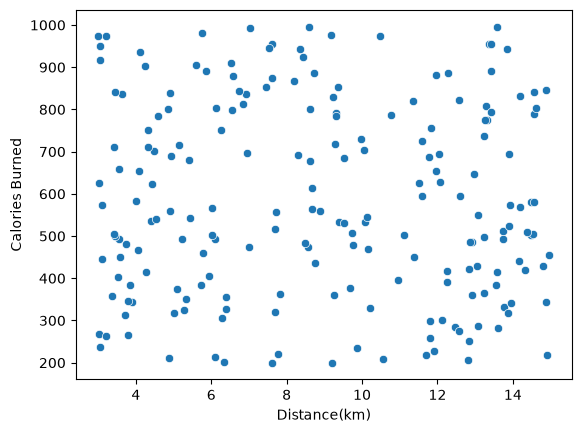

In [6]:
sns.scatterplot(data=df,x='Distance(km)',y='Calories Burned')

In [7]:
df['Distance(km)'].corr(df['Calories Burned'])

np.float64(-0.051362577737649844)

In [8]:
X = pd.DataFrame(df['Distance(km)'])
y = df['Calories Burned']

In [9]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=34);

In [10]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-3.07]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Distance(km)']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,597
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [11]:
model.coef_

array([-3.0714979])

In [12]:
model.intercept_

np.float64(597.0040866850538)

In [13]:
X_test.head()

,Distance(km)
74,6.95
10,9.97
183,5.40
195,3.21
87,3.74


In [14]:
y_test.head()

74     696
10     729
183    681
195    264
87     481
Name: Calories Burned, dtype: int64

In [15]:
model.predict(X_test)


array([575.65717625, 566.38125258, 580.417998  , 587.14457841,
       585.51668452, 570.34348488, 556.8288941 , 587.6053031 ,
       587.11386343, 555.78458481, 575.96432604, 586.49956385,
       560.69898146, 581.92303198, 583.76593072, 582.93662628,
       555.78458481, 553.41953143, 572.98497308, 579.37368872,
       581.92303198, 583.0594862 , 553.4502464 , 568.43915618,
       573.62998763, 556.36816941, 558.36464305, 554.24883586,
       566.71911735, 575.38074144, 551.30019787, 585.97740921,
       554.80170548, 568.16272137, 556.8288941 , 560.02325192,
       577.71507985, 559.37823736, 554.1874059 , 582.13803683])

In [16]:
y_pred = model.predict(X_test)
y_pred.shape


(40,)

In [17]:
comparison = pd.DataFrame({'actual':y_test,'predicted':y_pred})

In [18]:
comparison['error']=y_test-y_pred

In [19]:
comparison.head()

,actual,predicted,error
74,696,575.657176,120.342824
10,729,566.381253,162.618747
183,681,580.417998,100.582002
195,264,587.144578,-323.144578
87,481,585.516685,-104.516685


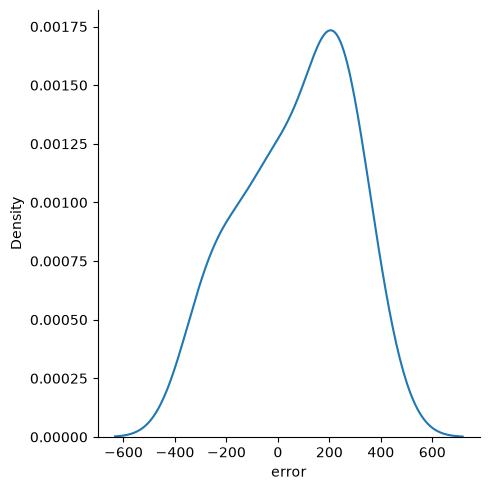

In [22]:
## The plot should be normally distrbuted as per assumption.
sns.displot(kind='kde',data=comparison,x='error')

In [20]:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = root_mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

In [21]:
print("Mean absolute error ",mae)
print("Mean squred error ",mse)
print("Root Mean squred error ",rmse)
print("R2 Score",r2)

Mean absolute error  189.87406003470892
Mean squred error  47934.09900069479
Root Mean squred error  218.9385735787433
R2 Score -0.12155773459317332
